# 2. Data reconciliation and the detection of gross errors

The measured flows of a plant do not close its mass balances. Data reconciliation finds the smallest adjustment, weighted by the accuracy of each instrument, that makes them close. The size of the adjustment is also a test: if it is larger than the noise can explain, an instrument is biased, and the lecture shows how to look for it.

## Learning objectives

1. State weighted data reconciliation as a constrained least-squares problem (`linear_physics.crowe_data_reconciliation`).
2. Check on a splitter with three streams that the adjustments are proportional to the variances of the instruments.
3. Reconcile the five streams of a reactor, separator and recycle.
4. Test for a biased flow meter with the chi-squared statistic of the adjustment and with the standardized adjustments of the single measurements.

**Time:** about 60 min

In [1]:
try:                      # use the installed package, or the copy in this repository
    import engml_2_applied
except ImportError:
    import pathlib, subprocess, sys
    for _root in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (_root / "engml_2_applied" / "__init__.py").exists():
            sys.path.insert(0, str(_root))
            break
    else:                 # on Google Colab: install from GitHub
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "git+https://github.com/ktwyw/engml-2-applied.git"], check=True)
    import engml_2_applied

import inspect
import numpy as np
import matplotlib.pyplot as plt
from engml_2_applied import (clustering_phases, constants, descriptors, dim_reduction, linear_physics,
                             trees_ensembles, uncertainty)
from engml_2_applied.plotting import panel_label, use_style

use_style()

def show_source(obj):
    """Return the source code of a library function or class."""
    return inspect.getsource(obj)

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## 1. Principles and governing equations
Given $d$ noisy plant flowrate measurements $\mathbf{y}_{\mathrm{meas}} \in \mathbb{R}^d$ ($\mathrm{kg/h}$) with diagonal sensor covariance matrix $\boldsymbol{\Sigma} = \mathrm{diag}(\sigma_1^2, \dots, \sigma_d^2)$ and $m$ nodal steady-state conservation balances $\mathbf{A}\mathbf{y} = \mathbf{b}$ ($\mathbf{A} \in \mathbb{R}^{m \times d}$), **Crowe's weighted data reconciliation (1983)** solves the maximum-likelihood problem:
$$\min_{\mathbf{y} \in \mathbb{R}^d} (\mathbf{y} - \mathbf{y}_{\mathrm{meas}})^\top \boldsymbol{\Sigma}^{-1}(\mathbf{y} - \mathbf{y}_{\mathrm{meas}}) \quad \text{subject to} \quad \mathbf{A}\mathbf{y} = \mathbf{b} \tag{1.1}$$
Letting $\mathbf{r} = \mathbf{A}\mathbf{y}_{\mathrm{meas}} - \mathbf{b} \in \mathbb{R}^m$ denote the raw nodal balance residuals with covariance $\mathbf{S}_r = \mathbf{A}\boldsymbol{\Sigma}\mathbf{A}^\top$, the closed-form reconciled flow vector is:
$$\hat{\mathbf{y}}_{\mathrm{rec}} = \mathbf{y}_{\mathrm{meas}} - \boldsymbol{\Sigma}\mathbf{A}^\top\left(\mathbf{A}\boldsymbol{\Sigma}\mathbf{A}^\top\right)^{-1}\mathbf{r} \tag{1.2}$$
Under the null hypothesis $H_0$ of zero-mean Gaussian noise ($\mathbf{y}_{\mathrm{meas}} \sim \mathcal{N}(\mathbf{y}_{\mathrm{true}}, \boldsymbol{\Sigma})$), the global gross-error statistic and individual standardized measurement test statistics follow exact distributions:
$$\chi^2_{\mathrm{stat}} = \mathbf{r}^\top \mathbf{S}_r^{-1}\mathbf{r} \sim \chi^2_m, \qquad z_{\mathrm{meas},i} = \frac{|\hat{y}_{\mathrm{rec},i} - y_{\mathrm{meas},i}|}{\sqrt{(\boldsymbol{\Sigma}\mathbf{A}^\top\mathbf{S}_r^{-1}\mathbf{A}\boldsymbol{\Sigma})_{ii}}} \sim |\mathcal{N}(0,1)| \tag{1.3}$$

In [2]:
heading("Demonstration 1: 3-Stream Splitter Pen-and-Paper Micro-Example")
# Splitter node: Feed F1 splits into Product F2 and Recycle F3 -> F1 - F2 - F3 = 0
A_split = np.array([[1.0, -1.0, -1.0]])
b_split = np.array([0.0])
y_meas_split = np.array([102.0, 60.0, 39.0])  # Raw imbalance r = 102 - 60 - 39 = +3.0 kg/h
sigma_split = np.array([1.0, 1.0, 2.0])       # Variances = [1, 1, 4], sum = 6.0

rec_split = linear_physics.crowe_data_reconciliation(y_meas_split, sigma_split, A_split, b_split)
# Exact hand calculation: adjustments proportional to variance [-1/6 * 3, +1/6 * 3, +4/6 * 3] = [-0.5, +0.5, +2.0]
assert np.allclose(rec_split["y_reconciled"], [101.5, 60.5, 41.0], atol=1e-14)
assert np.isclose(rec_split["chi2_stat"], (3.0 ** 2) / 6.0, rtol=1e-14)
print("Measured flows   [kg/h]:", y_meas_split, f"| Raw imbalance = {rec_split['balance_residual_before'][0]:+.2f} kg/h")
print("Reconciled flows [kg/h]:", rec_split["y_reconciled"], f"| New imbalance = {rec_split['balance_residual_after'][0]:+.1e} kg/h")
print(f"Adjustments      [kg/h]: {rec_split['y_reconciled'] - y_meas_split} (Proportional to variances [1, 1, 4])")
print(f"Global chi^2 statistic : {rec_split['chi2_stat']:.4f} (df = {rec_split['dof']})")


Demonstration 1: 3-Stream Splitter Pen-and-Paper Micro-Example
Measured flows   [kg/h]: [102.  60.  39.] | Raw imbalance = +3.00 kg/h
Reconciled flows [kg/h]: [101.5  60.5  41. ] | New imbalance = +0.0e+00 kg/h
Adjustments      [kg/h]: [-0.5  0.5  2. ] (Proportional to variances [1, 1, 4])
Global chi^2 statistic : 1.5000 (df = 1)


**What Demonstration 1 shows.** Stream 3 has twice the standard deviation ($\sigma_3 = 2.0\;\mathrm{kg/h}$, variance $4.0$) of Streams 1 and 2 ($\sigma_1=\sigma_2=1.0\;\mathrm{kg/h}$, variance $1.0$), so Crowe projection assigns $4/6 = 66.7\%$ of the $3.0\;\mathrm{kg/h}$ correction ($+2.0\;\mathrm{kg/h}$) to Stream 3.

---

## 2. Numerical walkthrough
Now consider a 5-stream, 3-node **Reactor–Separator–Recycle network**:
- **Streams:** $y_1$ (fresh feed, Coriolis $\sigma_1=0.5$), $y_2$ (reactor inlet, $\sigma_2=1.2$), $y_3$ (reactor outlet, $\sigma_3=1.2$), $y_4$ (overhead product, Coriolis $\sigma_4=0.5$), $y_5$ (recycle loop, Orifice $\sigma_5=2.0$).
- **Balances at the nodes ($\mathbf{A}_{\mathrm{net}}\mathbf{y} = \mathbf{0}$):** Mixer ($y_1 + y_5 - y_2 = 0$), Reactor ($y_2 - y_3 = 0$), Separator ($y_3 - y_4 - y_5 = 0$).

In [3]:
heading("Demonstration 2: 5-Stream Reactor-Separator-Recycle Incidence & Residual Covariance")
A_net = np.array([
    [1.0, -1.0,  0.0,  0.0,  1.0],  # Node 1: Mixer
    [0.0,  1.0, -1.0,  0.0,  0.0],  # Node 2: Reactor
    [0.0,  0.0,  1.0, -1.0, -1.0],  # Node 3: Separator
])
b_net = np.zeros(3)
y_true_net = np.array([100.0, 140.0, 140.0, 100.0, 40.0])
sigma_net = np.array([0.5, 1.2, 1.2, 0.5, 2.0])

rng = np.random.default_rng(101)
y_normal = y_true_net + rng.normal(0.0, sigma_net)
rec_normal = linear_physics.crowe_data_reconciliation(y_normal, sigma_net, A_net, b_net)
print("Raw nodal balance residuals [Mixer, Reactor, Separator]:", np.round(rec_normal["balance_residual_before"], 4))
print("Post-reconciliation nodal residuals                    :", np.round(rec_normal["balance_residual_after"], 15))
print(f"Normal operation chi^2 = {rec_normal['chi2_stat']:.3f} < chi^2_(3, 0.95) = 7.815 (No gross error alarm)")
assert np.max(np.abs(rec_normal["balance_residual_after"])) < 1e-13 and rec_normal["chi2_stat"] < 7.815


Demonstration 2: 5-Stream Reactor-Separator-Recycle Incidence & Residual Covariance
Raw nodal balance residuals [Mixer, Reactor, Separator]: [ 1.4271 -3.1655  0.9712]
Post-reconciliation nodal residuals                    : [-1.4e-14  0.0e+00  1.4e-14]
Normal operation chi^2 = 4.667 < chi^2_(3, 0.95) = 7.815 (No gross error alarm)


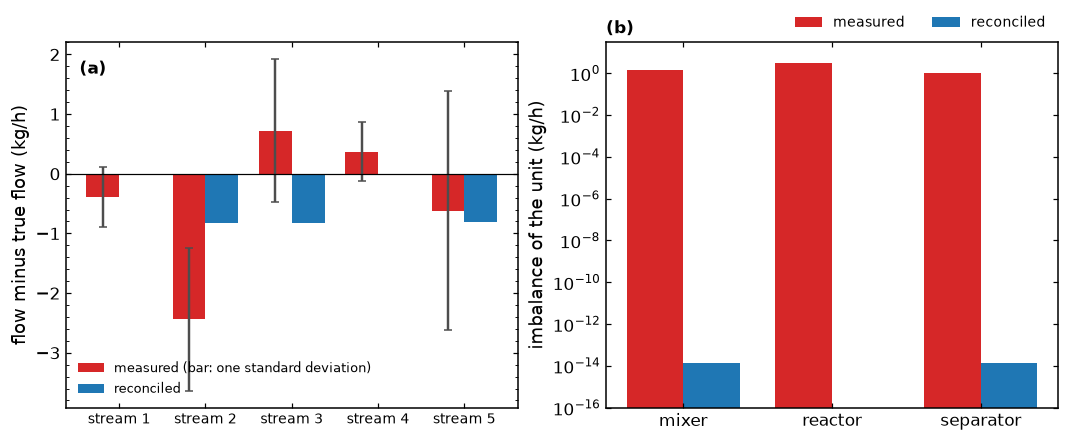

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
pos = np.arange(5); width = 0.38
ax1.bar(pos - width / 2, y_normal - y_true_net, width, yerr=sigma_net, color="C3", ecolor="0.3", label="measured (bar: one standard deviation)")
ax1.bar(pos + width / 2, rec_normal["y_reconciled"] - y_true_net, width, color="C0", label="reconciled")
ax1.axhline(0.0, color="k", lw=0.8); ax1.set_xticks(pos); ax1.set_xticklabels([f"stream {i}" for i in range(1, 6)], fontsize=9)
ax1.tick_params(axis="x", which="minor", bottom=False, top=False)
ax1.set_ylabel("flow minus true flow (kg/h)"); ax1.legend(fontsize=8.5, loc="lower left"); panel_label(ax1, "(a)")
nodes = ["mixer", "reactor", "separator"]; pos3 = np.arange(3)
ax2.bar(pos3 - width / 2, np.abs(A_net @ y_normal), width, color="C3", label="measured")
ax2.bar(pos3 + width / 2, np.maximum(np.abs(A_net @ rec_normal["y_reconciled"]), 1e-16), width, color="C0", label="reconciled")
ax2.set_yscale("log"); ax2.set_ylim(1e-16, 30.0); ax2.set_xticks(pos3); ax2.set_xticklabels(nodes)
ax2.tick_params(axis="x", which="minor", bottom=False, top=False)
ax2.set_ylabel("imbalance of the unit (kg/h)"); ax2.legend(fontsize=9, loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2); ax2.set_title("(b)", loc="left", fontweight="bold")
plt.show()

**Figure 2.1.** Reconciliation of five measured flows around a mixer, a reactor and a separator (synthetic data). (a) The error of each flow before and after; the meters with the larger standard deviations are adjusted more. (b) The imbalance of each unit, on a logarithmic scale: of the order of 1 kg/h in the measurements, and at rounding level after reconciliation.

**What Demonstration 2 shows.** With random noise only, the reconciled flows close the three unit balances to $10^{-14}\;\mathrm{kg/h}$, and the test statistic, $\chi^2 = 4.67$, is below the $95\ \%$ threshold for three degrees of freedom, $7.815$. The flows and their noise are synthetic.

---

## 3. Worked case study
What if Stream 3 (reactor outlet flowmeter) suffers a $+12.0\;\mathrm{kg/h}$ gross bias due to calibration drift? Let us inspect how a naive reconciliation without gross-error detection smears the $+12.0\;\mathrm{kg/h}$ bias across healthy meters, and how `measurement_z` pinpoints Stream 3.

In [5]:
heading("Demonstration 3: Gross-Error Injection & Faulty Sensor Isolation via Measurement z-Test")
y_faulty = y_normal.copy()
y_faulty[2] += 12.0  # Inject +12 kg/h gross bias into Stream 3 (Reactor Outlet flowmeter)
rec_faulty = linear_physics.crowe_data_reconciliation(y_faulty, sigma_net, A_net, b_net)
fault_sensor_idx = int(np.argmax(rec_faulty["measurement_z"]))

print(f"Faulty operation chi^2 = {rec_faulty['chi2_stat']:.2f} >> 7.815 (gross error alarm triggered)")
print(f"{'Stream':>8s} | {'True':>7s} | {'Measured':>9s} | {'Reconciled':>10s} | {'Meas z-score':>12s}")
print("-" * 58)
for i in range(5):
    flag = " <-- largest!" if i == fault_sensor_idx else ""
    print(f"Stream {i+1:1d} | {y_true_net[i]:7.2f} | {y_faulty[i]:9.2f} | {rec_faulty['y_reconciled'][i]:10.2f} | {rec_faulty['measurement_z'][i]:12.2f}{flag}")
assert rec_faulty["chi2_stat"] > 30.0 and fault_sensor_idx == 2


Demonstration 3: Gross-Error Injection & Faulty Sensor Isolation via Measurement z-Test
Faulty operation chi^2 = 87.91 >> 7.815 (gross error alarm triggered)
  Stream |    True |  Measured | Reconciled | Meas z-score
----------------------------------------------------------
Stream 1 |  100.00 |     99.60 |     100.14 |         1.49
Stream 2 |  140.00 |    137.56 |     144.28 |         7.40
Stream 3 |  140.00 |    152.72 |     144.28 |         9.28 <-- largest!
Stream 4 |  100.00 |    100.37 |     100.14 |         0.66
Stream 5 |   40.00 |     39.38 |      44.15 |         2.62


**What Demonstration 3 shows.** With a bias of $12\;\mathrm{kg/h}$ added to the meter of Stream 3, the global statistic is $\chi^2 = 87.9$, far above $7.815$. The measurement test is largest for Stream 3 ($z = 9.28$), which identifies the faulty meter. It is also large for Stream 2 ($z = 7.40$): the two streams enter the same balance, so a gross error in one is partly attributed to the other. The usual procedure is to remove the meter with the largest statistic, reconcile again, and repeat (Exercise 3).

---

## 4. What if: sensitivity to the parameters
Let us sweep the magnitude of the Stream 3 bias $\Delta y_3 \in [0, 12]\;\mathrm{kg/h}$ to map out the exact operating threshold where $\chi^2_{\mathrm{stat}}$ crosses the $95\%$ ($\chi^2_{3,0.95}=7.815$) and $99\%$ ($\chi^2_{3,0.99}=11.345$) detection limits.

In [6]:
heading("Demonstration 4: Gross-Error Magnitude Sweep & Chi-Squared Power Curve")
print(f"{'Bias dY_3 [kg/h]':>16s} | {'Global chi^2':>12s} | {'Max z_meas':>10s} | {'Isolated Stream':>15s} | {'Alarm Status':>14s}")
print("-" * 76)
for bias in [0.0, 2.0, 4.5, 7.0, 12.0]:
    y_sw = y_normal.copy()
    y_sw[2] += bias
    r_sw = linear_physics.crowe_data_reconciliation(y_sw, sigma_net, A_net, b_net)
    idx_max = int(np.argmax(r_sw["measurement_z"])) + 1
    status = "ALARM (>99%)" if r_sw["chi2_stat"] > 11.345 else ("WARN (>95%)" if r_sw["chi2_stat"] > 7.815 else "Normal")
    print(f"{bias:16.1f} | {r_sw['chi2_stat']:12.2f} | {np.max(r_sw['measurement_z']):10.2f} | {'Stream ' + str(idx_max):>15s} | {status:>14s}")


Demonstration 4: Gross-Error Magnitude Sweep & Chi-Squared Power Curve
Bias dY_3 [kg/h] | Global chi^2 | Max z_meas | Isolated Stream |   Alarm Status
----------------------------------------------------------------------------
             0.0 |         4.67 |       1.78 |        Stream 2 |         Normal
             2.0 |        10.57 |       2.97 |        Stream 3 |    WARN (>95%)
             4.5 |        22.42 |       4.55 |        Stream 3 |   ALARM (>99%)
             7.0 |        39.27 |       6.12 |        Stream 3 |   ALARM (>99%)
            12.0 |        87.91 |       9.28 |        Stream 3 |   ALARM (>99%)


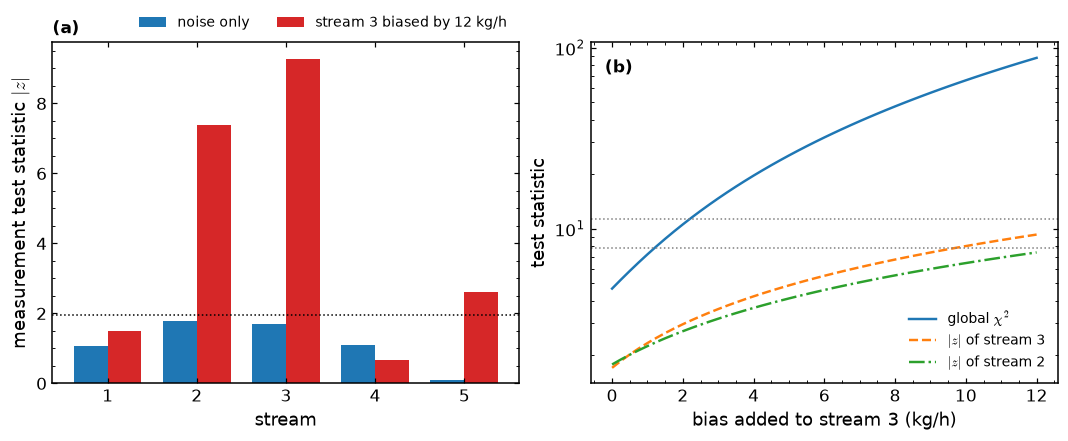

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
ax1.bar(np.arange(1, 6) - 0.19, rec_normal["measurement_z"], 0.38, color="C0", label="noise only")
ax1.bar(np.arange(1, 6) + 0.19, rec_faulty["measurement_z"], 0.38, color="C3", label="stream 3 biased by 12 kg/h")
ax1.axhline(1.96, color="k", ls=":", lw=1.0)
ax1.set_xlabel("stream"); ax1.set_ylabel("measurement test statistic $|z|$"); ax1.tick_params(axis="x", which="minor", bottom=False, top=False)
ax1.legend(fontsize=9, loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2); ax1.set_title("(a)", loc="left", fontweight="bold")
bias_line = np.linspace(0.0, 12.0, 49); chi_line, z3_line, z2_line = [], [], []
for bias in bias_line:
    y_sw = y_normal.copy(); y_sw[2] += bias
    r_sw = linear_physics.crowe_data_reconciliation(y_sw, sigma_net, A_net, b_net)
    chi_line.append(r_sw["chi2_stat"]); z3_line.append(r_sw["measurement_z"][2]); z2_line.append(r_sw["measurement_z"][1])
ax2.semilogy(bias_line, chi_line, label=r"global $\chi^2$")
ax2.semilogy(bias_line, z3_line, "--", label="$|z|$ of stream 3"); ax2.semilogy(bias_line, z2_line, "-.", label="$|z|$ of stream 2")
ax2.axhline(7.815, color="0.5", ls=":", lw=1.0); ax2.axhline(11.345, color="0.5", ls=":", lw=1.0)
ax2.set_xlabel("bias added to stream 3 (kg/h)"); ax2.set_ylabel("test statistic"); ax2.legend(fontsize=9, loc="lower right"); panel_label(ax2, "(b)")
plt.show()

**Figure 2.2.** Detection of a gross error. (a) The measurement test for each stream, with random noise only and with a bias on stream 3; the dotted line is the 95 % limit of a standard normal variable. The bias also raises the statistic of stream 2, which shares a balance with stream 3. (b) The global statistic and the two measurement statistics against the size of the bias; the dotted lines are the 95 % and 99 % limits of the $\chi^2$ distribution with three degrees of freedom.

**What Demonstration 4 shows.** A bias of $2\;\mathrm{kg/h}$ in Stream 3 already takes the global statistic past the $95\ \%$ threshold ($10.6 > 7.815$), and from $4.5\;\mathrm{kg/h}$ it is past the $99\ \%$ threshold as well. In every case with a bias, the largest measurement statistic is that of Stream 3.

---

## Inside the algorithm
Below we verify a pure-NumPy covariance-weighted projection $\hat{\mathbf{y}} = \mathbf{y}_{\mathrm{meas}} - \boldsymbol{\Sigma}\mathbf{A}^\top(\mathbf{A}\boldsymbol{\Sigma}\mathbf{A}^\top)^{-1}(\mathbf{A}\mathbf{y}_{\mathrm{meas}} - \mathbf{b})$ against `linear_physics.crowe_data_reconciliation`.

In [8]:
heading("Inside the Algorithm: By-Hand Crowe Projection vs. the Library")
Sigma_mat = np.diag(sigma_net ** 2)
r_vec = A_net @ y_normal - b_net
S_r_mat = A_net @ Sigma_mat @ A_net.T
y_rec_hand = y_normal - Sigma_mat @ A_net.T @ np.linalg.solve(S_r_mat, r_vec)
diff_crowe = float(np.max(np.abs(y_rec_hand - rec_normal["y_reconciled"])))
print("by hand (pure NumPy):", np.round(y_rec_hand, 6))
print("library (engml_2_applied)     :", np.round(rec_normal["y_reconciled"], 6))
print(f"Max discrepancy     : {diff_crowe:.2e}")
assert diff_crowe < 1e-13


Inside the Algorithm: By-Hand Crowe Projection vs. the Library
by hand (pure NumPy): [ 99.982654 139.175082 139.175082  99.982654  39.192427]
library (engml_2_applied)     : [ 99.982654 139.175082 139.175082  99.982654  39.192427]
Max discrepancy     : 0.00e+00


## Exercises

1. **Verify a result.** In the 5-stream reactor-separator network (`A_net`, `b_net`, `sigma_net`), inject a $-10.0\;\mathrm{kg/h}$ gross bias into the recycle orifice meter (Stream 5, index `4`) on top of `y_true_net`. Run `crowe_data_reconciliation`, verify that $\chi^2_{\mathrm{stat}} > 15.0$, and confirm that `np.argmax(rec['measurement_z']) == 4` isolates Stream 5.
2. **Find how it fails.** Quantify the smearing damage caused by reconciling a flowsheet *without* removing a faulty sensor first: compare the mean absolute error (MAE) across the 4 healthy streams (`[0, 1, 3, 4]`) when `y_faulty` (with the $+12\;\mathrm{kg/h}$ bias on Stream 3) is reconciled directly, versus replacing the faulty Stream 3 uncertainty with a huge dummy standard deviation $\sigma_3 = 1000\;\mathrm{kg/h}$ (effectively unweighting the broken meter).
3. **Write it yourself.** Implement an automated gross-error elimination function `iterative_crowe_reconcile(y_meas, sigma_meas, A, b, chi2_threshold=7.815)` that checks $\chi^2_{\mathrm{stat}} > \chi^2_{\mathrm{threshold}}$, identifies the sensor with maximum `measurement_z`, inflates its standard deviation by $10^4\times$ to remove its corrupting leverage, and re-runs Crowe reconciliation. Verify it on `y_faulty`.

The cell below works Exercise 1 as a first check; all three are solved in the solutions notebook of this lecture.

In [9]:
heading("Exercise 1: Recycle Orifice Meter Gross-Error Isolation")
y_bias5 = y_true_net.copy()
y_bias5[4] -= 10.0
rec_bias5 = linear_physics.crowe_data_reconciliation(y_bias5, sigma_net, A_net, b_net)
isolated_idx = int(np.argmax(rec_bias5["measurement_z"]))
print(f"Recycle fault chi^2 = {rec_bias5['chi2_stat']:.2f} | Isolated stream index = {isolated_idx} (z = {rec_bias5['measurement_z'][isolated_idx]:.2f})")
assert rec_bias5["chi2_stat"] > 15.0 and isolated_idx == 4
assert np.max(np.abs(rec_bias5["balance_residual_after"])) < 1e-13


Exercise 1: Recycle Orifice Meter Gross-Error Isolation
Recycle fault chi^2 = 20.64 | Isolated stream index = 4 (z = 4.54)
